In [1]:
import os
import urllib.request
import pandas as pd

# শুধু আপনার API Token / Key এখানে বসান (username লাগবে না)
API_TOKEN = "PASTE API TOKEN HERE"

!pip install -q kaggle xgboost scikit-learn pandas numpy matplotlib seaborn

os.makedirs("./data", exist_ok=True)
csv_path = "./data/diabetes.csv"
downloaded = False

# ১ম চেষ্টা: API Token দিয়ে Kaggle CLI / API
if API_TOKEN and API_TOKEN != "PASTE_YOUR_KAGGLE_API_TOKEN_HERE":
    # Kaggle নতুন token (KGAT_...) হলে KAGGLE_API_TOKEN হিসেবেও কাজ করে, পুরনো key হলে KAGGLE_KEY হিসেবে
    os.environ["KAGGLE_API_TOKEN"] = API_TOKEN
    os.environ["KAGGLE_KEY"] = API_TOKEN
    ret = os.system("kaggle datasets download -d uciml/pima-indians-diabetes-database --unzip -p ./data")
    if ret == 0 and os.path.exists(csv_path):
        downloaded = True

# ২য় চেষ্টা (যদি 403 বা অন্য কোনো error আসে): সরাসরি পাবলিক CSV সোর্স থেকে নামিয়ে নেওয়া
if not downloaded:
    fallback_urls = [
        "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv",
        "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
    ]
    for idx, url in enumerate(fallback_urls):
        try:
            urllib.request.urlretrieve(url, csv_path)
            if idx == 1:
                cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                        'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
                df_tmp = pd.read_csv(csv_path, names=cols)
                df_tmp.to_csv(csv_path, index=False)
            if os.path.exists(csv_path):
                downloaded = True
                break
        except Exception as e:
            print("Fallback attempt error:", e)

print("Ready to load data:", os.path.exists(csv_path))

Ready to load data: True


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("./data/diabetes.csv")
print("Dataset Shape:", df.shape)
display(df.head())

# মেডিকেল ডেটায় Glucose, BloodPressure, SkinThickness, Insulin, BMI এর 0 মানকে missing ধরে median দিয়ে পূরণ
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[zero_cols] = df[zero_cols].replace(0, np.nan)
df.fillna(df.median(), inplace=True)

X = df.drop(columns=['Outcome'])
y = df['Outcome']

SEED = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing completed successfully.")

Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Preprocessing completed successfully.


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

models = {
    'Logistic Regression': LogisticRegression(random_state=SEED, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=SEED, eval_metric='logloss')
}

results = []

for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    })

results_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False)
display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,XGBoost,0.7727,0.7021,0.6111,0.6535,0.8154
1,Random Forest,0.7792,0.7273,0.5926,0.6531,0.8192
0,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130


Best Performing Model: XGBoost

              precision    recall  f1-score   support

Non-Diabetic       0.80      0.86      0.83       100
    Diabetic       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154



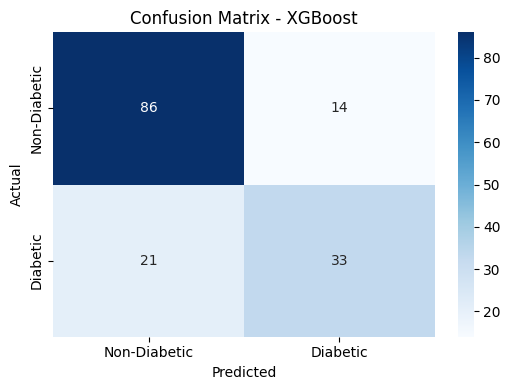

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

print(f"Best Performing Model: {best_model_name}\n")

if best_model_name == 'Logistic Regression':
    y_best_pred = best_model.predict(X_test_scaled)
else:
    y_best_pred = best_model.predict(X_test)

print(classification_report(y_test, y_best_pred, target_names=['Non-Diabetic', 'Diabetic']))

cm = confusion_matrix(y_test, y_best_pred)
plt.figure(figsize=(5.5, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

In [5]:
import os
import zipfile
from google.colab import files

zip_filename = "CodeAlpha_Disease_Prediction.zip"

# যেসব ফাইল বা ফোল্ডার zip-এ রাখতে চান (যেগুলো আছে শুধু সেগুলোই নেওয়া হবে)
targets = ["./data"]

# চাইলে confusion matrix বা model save করেও এখানে রাখতে পারেন
with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    for target in targets:
        if os.path.isfile(target):
            zipf.write(target, os.path.basename(target))
        elif os.path.isdir(target):
            for root, _, filenames in os.walk(target):
                for filename in filenames:
                    full_path = os.path.join(root, filename)
                    arcname = os.path.relpath(full_path, start=".")
                    zipf.write(full_path, arcname)

print("Created zip:", zip_filename, "| Size (bytes):", os.path.getsize(zip_filename))

# সরাসরি পিসিতে ডাউনলোড শুরু হবে
files.download(zip_filename)

Created zip: CodeAlpha_Disease_Prediction.zip | Size (bytes): 8979


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>